# 02 — Resource Prediction Model

**Goal:** Train and compare ML models that predict daily resource requirements for a
displaced-population camp: food, water, shelter, and medical staff.

**Input :** `data/processed/camp_features.csv` — built by notebook 01  
**Output:** `models/resource_model_<target>.pkl` — one saved model per resource type

**Targets (UNHCR Sphere standards):**
- `food_kg_day` — kg of dry rations per day
- `water_liters_day` — litres of water per day
- `shelter_units` — shelter units needed
- `medical_staff_needed` — health workers needed

## 1. Imports & Config

In [10]:
import sys
!{sys.executable} -m pip install joblib scikit-learn


In [11]:
import sys
!{sys.executable} -m pip install xgboost lightgbm

In [12]:
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib
from pathlib import Path

from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.linear_model import Ridge
from xgboost import XGBRegressor
from lightgbm import LGBMRegressor

PROCESSED  = Path('../data/processed')
MODELS_DIR = Path('../models')
MODELS_DIR.mkdir(exist_ok=True)

RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)

TARGET_COLS = ['food_kg_day', 'water_liters_day', 'shelter_units', 'medical_staff_needed']

FEATURE_COLS = [
    'year',
    'refugees', 'asylum_seekers', 'returned_refugees',
    'idps', 'returned_idps', 'stateless', 'ooc',
    'total_population',
    'children_ratio', 'elderly_ratio', 'female_ratio',
    'yearly_arrivals', 'arrival_growth_rate',
]

print('Imports OK')

Imports OK


In [13]:
camp_path = PROCESSED / 'camp_features.csv'

if not camp_path.exists():
    raise FileNotFoundError(
        'camp_features.csv not found.\n'
        'Please run notebook 01_explore_kaggle_data.ipynb first.'
    )

df = pd.read_csv(camp_path, low_memory=False)
print(f'Loaded: {df.shape[0]:,} rows x {df.shape[1]} cols')
print(f'Years : {df.year.min()} - {df.year.max()}')
print()

# Verify all expected columns are present
missing = [c for c in FEATURE_COLS + TARGET_COLS if c not in df.columns]
if missing:
    raise ValueError(f'Missing columns in data: {missing}')
print('All feature and target columns present.')
df[FEATURE_COLS + TARGET_COLS].describe()

Loaded: 2,251 rows x 18 cols
Years : 2010 - 2022

All feature and target columns present.


,year,refugees,asylum_seekers,returned_refugees,idps,returned_idps,stateless,ooc,total_population,children_ratio,elderly_ratio,female_ratio,yearly_arrivals,arrival_growth_rate,food_kg_day,water_liters_day,shelter_units,medical_staff_needed
count,2251.000000,2.251000e+03,2.251000e+03,2251.000000,2.251000e+03,2.251000e+03,2251.000000,2.251000e+03,2.251000e+03,2251.000000,2251.000000,2251.000000,2251.000000,2251.000000,2.251000e+03,2.251000e+03,2.251000e+03,2251.000000
mean,2016.038649,9.904213e+04,1.624302e+04,2115.596624,2.040921e+05,2.033112e+04,21784.150155,1.259603e+04,3.762041e+05,0.288197,0.034178,0.433390,2176.714349,0.039720,2.257225e+05,7.524083e+06,8.360092e+04,1036.319991
std,3.730573,3.074757e+05,7.674719e+04,13239.600157,8.524656e+05,1.253678e+05,105073.186692,1.082527e+05,1.022216e+06,0.122720,0.029666,0.079904,20295.604855,0.411752,6.133297e+05,2.044432e+07,2.271591e+05,2805.164860
min,2010.000000,0.000000e+00,0.000000e+00,0.000000,0.000000e+00,0.000000e+00,0.000000,0.000000e+00,5.000000e+00,0.000000,0.000000,0.000000,0.000000,-0.990296,3.000000e+00,1.000000e+02,1.000000e+00,0.000000
25%,2013.000000,3.105000e+02,5.600000e+01,0.000000,0.000000e+00,0.000000e+00,0.000000,0.000000e+00,2.099000e+03,0.262986,0.029971,0.446770,0.000000,0.000000,1.259400e+03,4.198000e+04,4.660000e+02,5.300000
50%,2016.000000,4.050000e+03,6.540000e+02,0.000000,0.000000e+00,0.000000e+00,0.000000,0.000000e+00,2.179700e+04,0.262986,0.029971,0.446770,0.000000,0.000000,1.307820e+04,4.359400e+05,4.844000e+03,60.000000
75%,2019.000000,5.650250e+04,6.518000e+03,43.000000,0.000000e+00,0.000000e+00,1200.000000,8.000000e+00,2.265485e+05,0.262986,0.029971,0.446770,0.000000,0.000000,1.359291e+05,4.530970e+06,5.034400e+04,624.050000
max,2022.000000,3.759817e+06,1.798792e+06,381275.000000,8.252788e+06,2.134349e+06,955399.000000,3.206577e+06,8.773689e+06,0.926872,0.303877,0.764706,721778.000000,5.000000,5.264213e+06,1.754738e+08,1.949709e+06,28752.200000


## 3. Feature Engineering

Add log-scale versions of the large population counts — this helps
linear/regularised models deal with the extreme skew in refugee numbers.

In [15]:
df_feat = df.copy()

# Log1p transform of count columns to reduce skew
COUNT_COLS = ['refugees', 'asylum_seekers', 'idps', 'stateless', 'ooc',
              'total_population', 'yearly_arrivals']
for col in COUNT_COLS:
    df_feat[f'log_{col}'] = np.log1p(df_feat[col])

# Years since 2010 (relative time index)
df_feat['years_elapsed'] = df_feat['year'] - 2010

# Vulnerability index: higher when more children + elderly
df_feat['vulnerability_index'] = df_feat['children_ratio'] + df_feat['elderly_ratio']

# Extended feature list including engineered features
FEATURE_COLS_EXT = FEATURE_COLS + [
    'log_refugees', 'log_asylum_seekers', 'log_idps',
    'log_total_population', 'log_yearly_arrivals',
    'years_elapsed', 'vulnerability_index',
]

print(f'Extended feature set: {len(FEATURE_COLS_EXT)} features')
print(FEATURE_COLS_EXT)

Extended feature set: 21 features
['year', 'refugees', 'asylum_seekers', 'returned_refugees', 'idps', 'returned_idps', 'stateless', 'ooc', 'total_population', 'children_ratio', 'elderly_ratio', 'female_ratio', 'yearly_arrivals', 'arrival_growth_rate', 'log_refugees', 'log_asylum_seekers', 'log_idps', 'log_total_population', 'log_yearly_arrivals', 'years_elapsed', 'vulnerability_index']


## 4. Train/Test Split

80/20 split with `random_state` fixed for reproducibility.

In [16]:
X = df_feat[FEATURE_COLS_EXT].fillna(0)

X_train, X_test = train_test_split(X, test_size=0.2, random_state=RANDOM_STATE)

scaler       = StandardScaler()
X_train_sc   = scaler.fit_transform(X_train)
X_test_sc    = scaler.transform(X_test)
train_idx    = X_train.index
test_idx     = X_test.index

print(f'Train : {X_train.shape[0]:,} samples')
print(f'Test  : {X_test.shape[0]:,} samples')

Train : 1,800 samples
Test  : 451 samples


## 5. Define Models

In [17]:
MODELS = {
    'Ridge':            Ridge(alpha=10.0),
    'RandomForest':     RandomForestRegressor(n_estimators=200, max_depth=12,
                                              random_state=RANDOM_STATE, n_jobs=-1),
    'GradientBoosting': GradientBoostingRegressor(n_estimators=200, learning_rate=0.05,
                                                   max_depth=5, random_state=RANDOM_STATE),
    'XGBoost':          XGBRegressor(n_estimators=200, learning_rate=0.05,
                                     max_depth=6, random_state=RANDOM_STATE,
                                     verbosity=0, n_jobs=-1),
    'LightGBM':         LGBMRegressor(n_estimators=200, learning_rate=0.05,
                                      max_depth=6, random_state=RANDOM_STATE,
                                      verbose=-1, n_jobs=-1),
}
print(f'Models to compare: {list(MODELS.keys())}')

Models to compare: ['Ridge', 'RandomForest', 'GradientBoosting', 'XGBoost', 'LightGBM']


## 6. Train & Evaluate — All Targets

We train all 5 models on each of the 4 resource targets and compare by R², MAE, and RMSE.

In [18]:
all_results = {}
trained_models = {}

for target in TARGET_COLS:
    y_train = df_feat.loc[train_idx, target].fillna(0)
    y_test  = df_feat.loc[test_idx,  target].fillna(0)

    results = []
    target_models = {}

    print(f'\n{"="*60}')
    print(f'  TARGET: {target}')
    print(f'{"="*60}')

    for name, model in MODELS.items():
        import copy
        m = copy.deepcopy(model)

        use_scaled = name == 'Ridge'
        Xtr = X_train_sc if use_scaled else X_train
        Xte = X_test_sc  if use_scaled else X_test

        m.fit(Xtr, y_train)
        preds = m.predict(Xte)

        mae  = mean_absolute_error(y_test, preds)
        rmse = np.sqrt(mean_squared_error(y_test, preds))
        r2   = r2_score(y_test, preds)

        results.append({'Model': name, 'MAE': mae, 'RMSE': rmse, 'R2': r2})
        target_models[name] = m
        print(f'  {name:<20} R2={r2:.4f}  MAE={mae:,.1f}  RMSE={rmse:,.1f}')

    results_df = pd.DataFrame(results).sort_values('R2', ascending=False)
    all_results[target]    = results_df
    trained_models[target] = target_models

print('\nTraining complete.')


  TARGET: food_kg_day
  Ridge                R2=1.0000  MAE=1,059.9  RMSE=2,137.5
  RandomForest         R2=0.9996  MAE=1,843.1  RMSE=11,047.0
  GradientBoosting     R2=0.9999  MAE=1,278.3  RMSE=5,541.0
  XGBoost              R2=0.9979  MAE=5,432.8  RMSE=26,166.4
  LightGBM             R2=0.9884  MAE=9,272.3  RMSE=61,524.8

  TARGET: water_liters_day
  Ridge                R2=1.0000  MAE=35,329.9  RMSE=71,250.2
  RandomForest         R2=0.9997  MAE=56,504.2  RMSE=320,496.7
  GradientBoosting     R2=0.9999  MAE=42,610.1  RMSE=184,701.6
  XGBoost              R2=0.9979  MAE=181,883.1  RMSE=876,336.4
  LightGBM             R2=0.9884  MAE=309,077.5  RMSE=2,050,826.1

  TARGET: shelter_units
  Ridge                R2=1.0000  MAE=392.5  RMSE=791.7
  RandomForest         R2=0.9996  MAE=687.4  RMSE=4,239.9
  GradientBoosting     R2=0.9999  MAE=477.9  RMSE=2,079.9
  XGBoost              R2=0.9979  MAE=2,003.7  RMSE=9,654.8
  LightGBM             R2=0.9883  MAE=3,430.3  RMSE=22,854.3

  TARGET:

## 7. Best Model Per Target

In [19]:
print(f'{"Target":<28} {"Best Model":<22} {"R2":>8} {"MAE":>14} {"RMSE":>14}')
print('-' * 90)

best_per_target = {}
for target in TARGET_COLS:
    top = all_results[target].iloc[0]
    best_per_target[target] = top['Model']
    print(f'{target:<28} {top["Model"]:<22} {top["R2"]:>8.4f} {top["MAE"]:>14,.1f} {top["RMSE"]:>14,.1f}')

Target                       Best Model                   R2            MAE           RMSE
------------------------------------------------------------------------------------------
food_kg_day                  Ridge                    1.0000        1,059.9        2,137.5
water_liters_day             Ridge                    1.0000       35,329.9       71,250.2
shelter_units                Ridge                    1.0000          392.5          791.7
medical_staff_needed         GradientBoosting         0.9971           31.3          141.6


## 8. Visualise Model Comparison

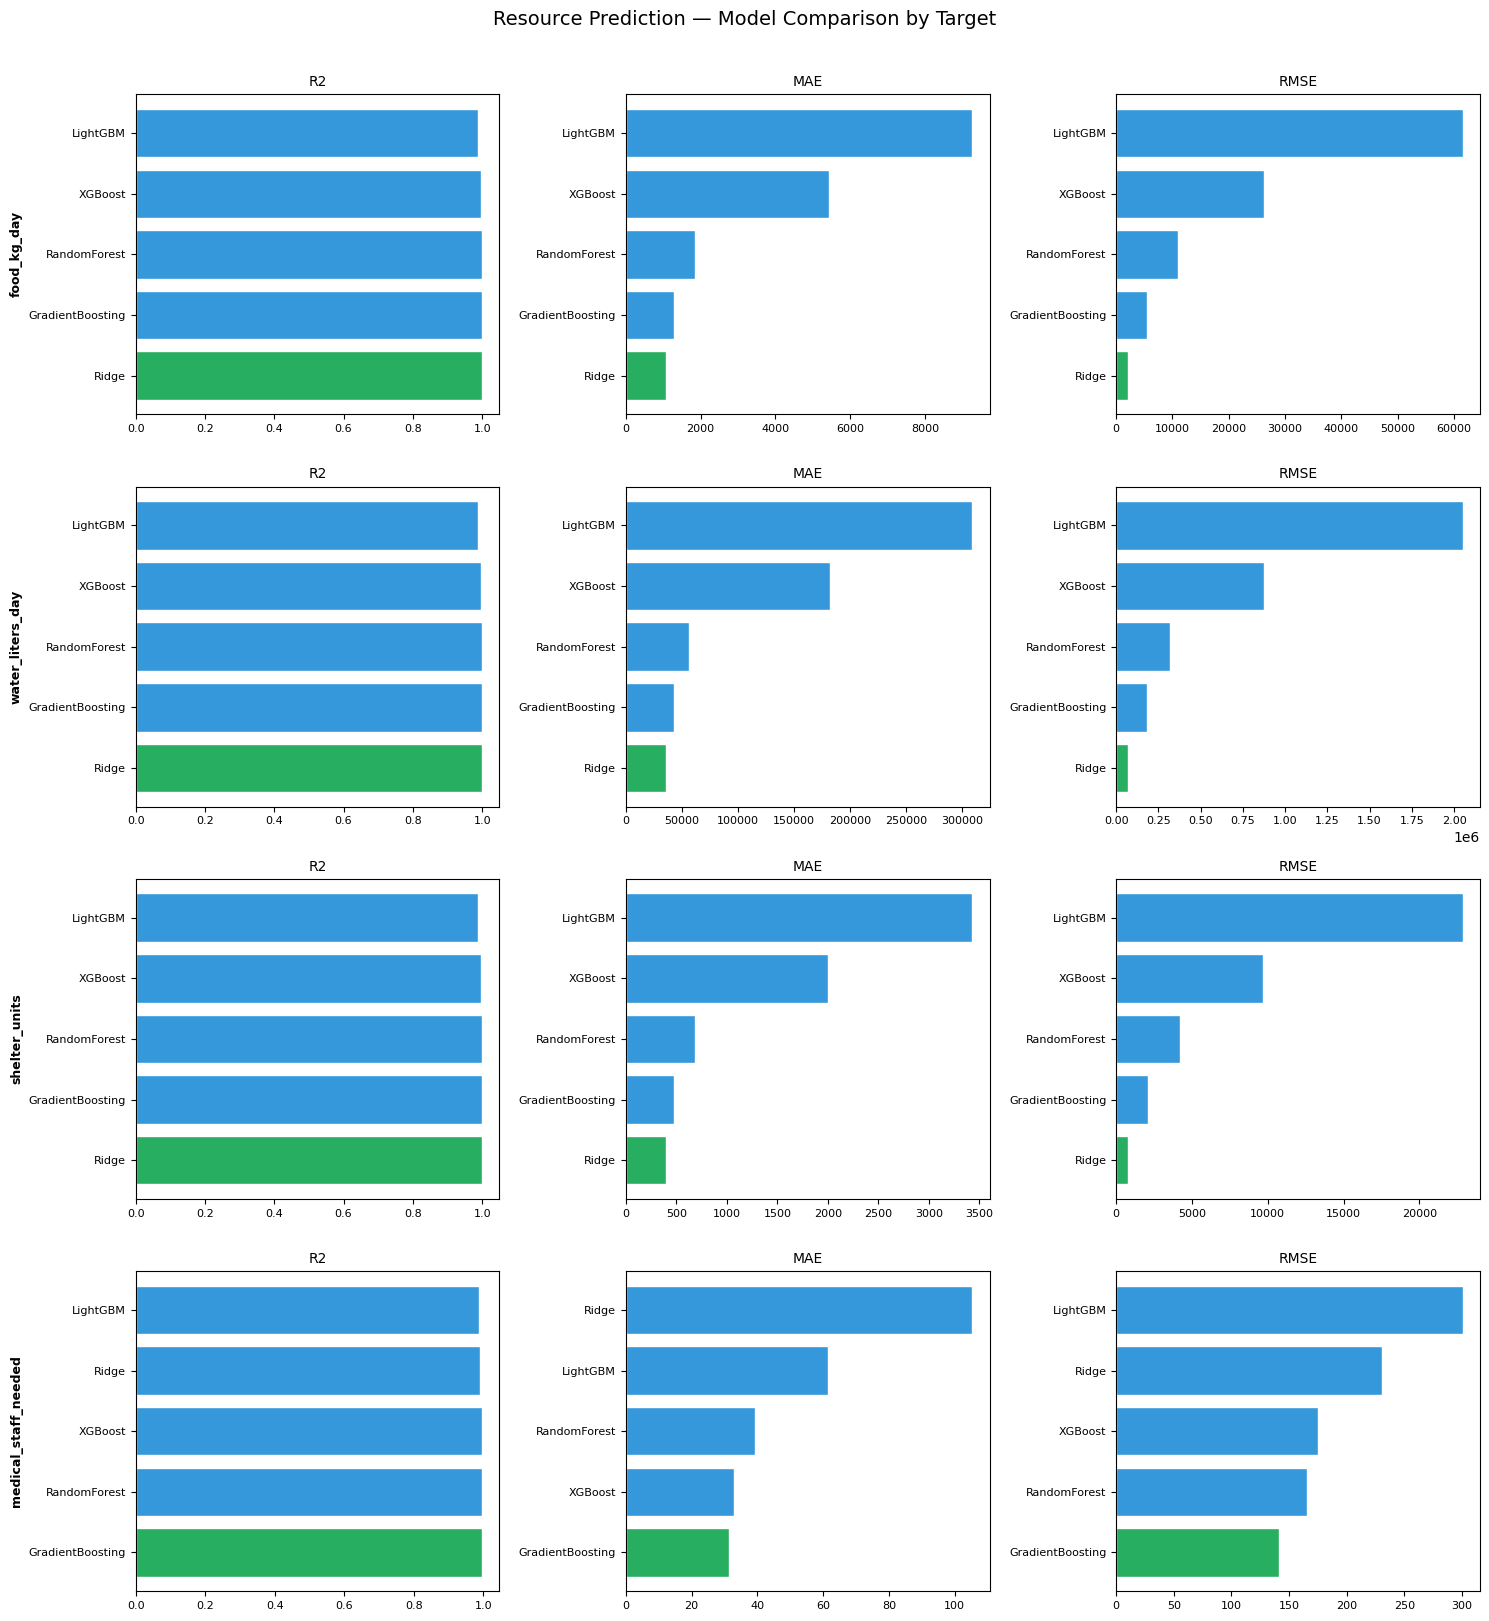

In [20]:
fig, axes = plt.subplots(len(TARGET_COLS), 3, figsize=(15, 4 * len(TARGET_COLS)))

for row_idx, target in enumerate(TARGET_COLS):
    df_res = all_results[target]
    for col_idx, metric in enumerate(['R2', 'MAE', 'RMSE']):
        ax = axes[row_idx][col_idx]
        ascending = metric != 'R2'
        data = df_res.sort_values(metric, ascending=ascending)
        colors = ['#27ae60' if i == 0 else '#3498db' for i in range(len(data))]
        ax.barh(data['Model'], data[metric], color=colors, edgecolor='white')
        if col_idx == 0:
            ax.set_ylabel(target, fontsize=9, fontweight='bold')
        ax.set_title(metric, fontsize=10)
        ax.tick_params(labelsize=8)

plt.suptitle('Resource Prediction — Model Comparison by Target', fontsize=14, y=1.01)
plt.tight_layout()
plt.show()

## 9. Feature Importance — Best Models

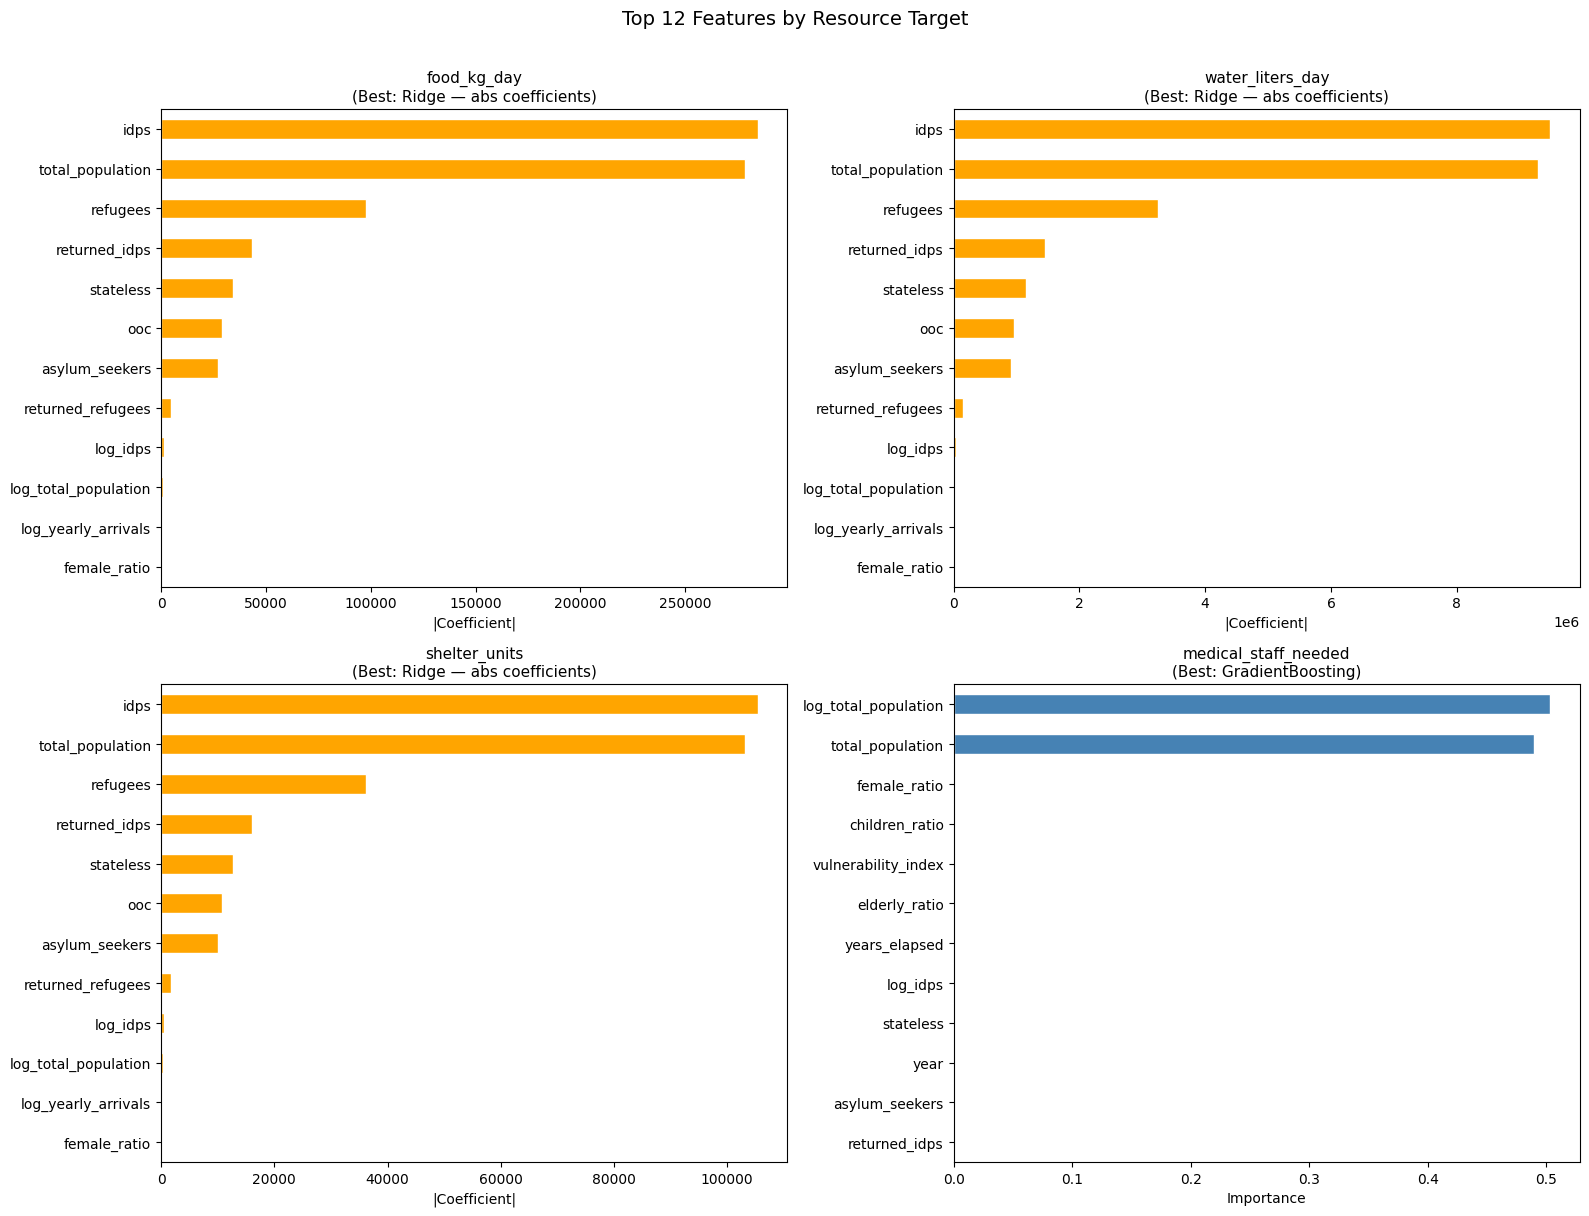

In [21]:
fig, axes = plt.subplots(2, 2, figsize=(16, 12))
axes = axes.flat

for ax, target in zip(axes, TARGET_COLS):
    best_name  = best_per_target[target]
    best_model = trained_models[target][best_name]

    if hasattr(best_model, 'feature_importances_'):
        importance = pd.Series(best_model.feature_importances_, index=FEATURE_COLS_EXT)
        importance = importance.nlargest(12).sort_values()
        importance.plot(kind='barh', ax=ax, color='steelblue', edgecolor='white')
        ax.set_title(f'{target}\n(Best: {best_name})', fontsize=11)
        ax.set_xlabel('Importance')
    else:
        # Ridge — show coefficients
        coefs = pd.Series(np.abs(best_model.coef_), index=FEATURE_COLS_EXT)
        coefs = coefs.nlargest(12).sort_values()
        coefs.plot(kind='barh', ax=ax, color='orange', edgecolor='white')
        ax.set_title(f'{target}\n(Best: {best_name} — abs coefficients)', fontsize=11)
        ax.set_xlabel('|Coefficient|')

plt.suptitle('Top 12 Features by Resource Target', fontsize=14, y=1.01)
plt.tight_layout()
plt.show()

## 10. Actual vs Predicted — Best Models

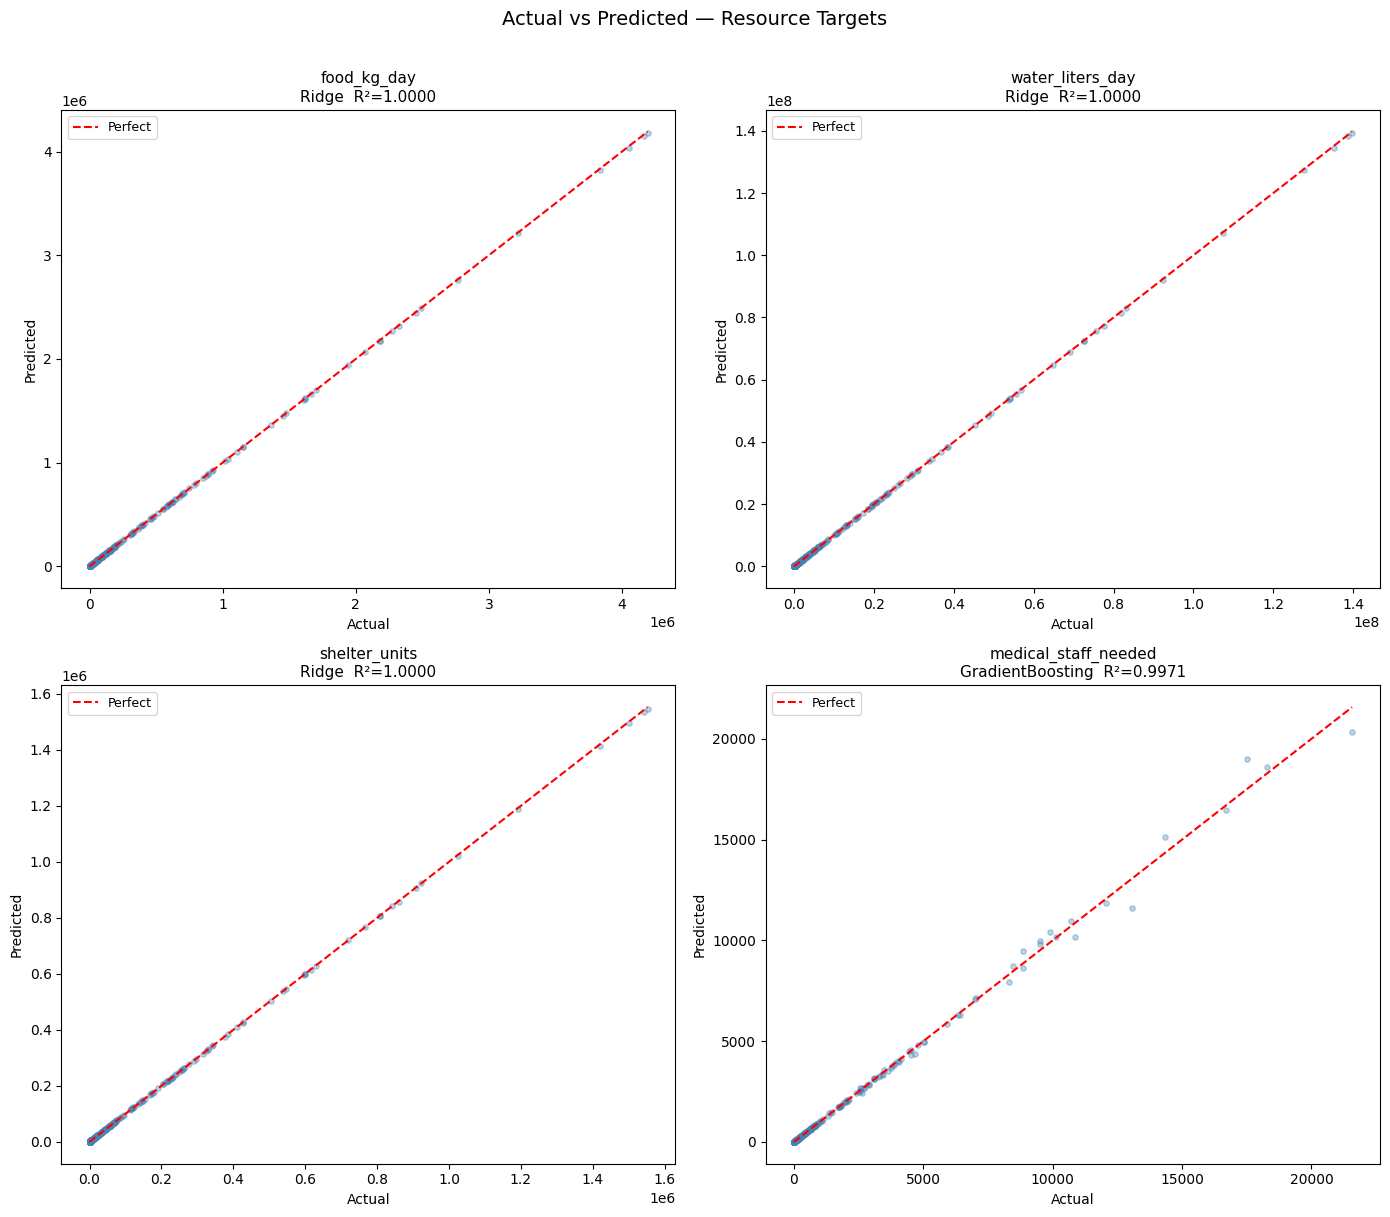

In [ ]:
fig, axes = plt.subplots(2, 2, figsize=(14, 12))
axes = axes.flat

for ax, target in zip(axes, TARGET_COLS):
    best_name  = best_per_target[target]
    best_model = trained_models[target][best_name]

    use_scaled = best_name == 'Ridge'
    preds = best_model.predict(X_test_sc if use_scaled else X_test)
    y_test = df_feat.loc[test_idx, target].fillna(0)

    ax.scatter(y_test, preds, alpha=0.35, s=15, color='steelblue')
    lims = [min(y_test.min(), preds.min()), max(y_test.max(), preds.max())]
    ax.plot(lims, lims, 'r--', linewidth=1.5, label='Perfect')
    r2 = r2_score(y_test, preds)
    ax.set_title(f'{target}\n{best_name}  R²={r2:.4f}', fontsize=11)
    ax.set_xlabel('Actual')
    ax.set_ylabel('Predicted')
    ax.legend(fontsize=9)

plt.suptitle('Actual vs Predicted — Resource Targets', fontsize=14, y=1.01)
plt.tight_layout()
plt.show()

## 11. Save All Best Models

In [23]:
all_meta = {}

for target in TARGET_COLS:
    best_name  = best_per_target[target]
    best_model = trained_models[target][best_name]
    top_row    = all_results[target].iloc[0]

    model_file = MODELS_DIR / f'resource_model_{target}.pkl'
    joblib.dump(best_model, model_file)

    meta = {
        'target':     target,
        'model_type': best_name,
        'features':   FEATURE_COLS_EXT,
        'r2':         float(top_row['R2']),
        'mae':        float(top_row['MAE']),
        'rmse':       float(top_row['RMSE']),
    }
    all_meta[target] = meta
    print(f'Saved {model_file.name}  (R2={meta["r2"]:.4f})')

# Save shared scaler
joblib.dump(scaler, MODELS_DIR / 'resource_scaler.pkl')

# Save combined metadata
meta_path = MODELS_DIR / 'resource_models_meta.json'
meta_path.write_text(json.dumps(all_meta, indent=2))

print()
print('All models, scaler, and metadata saved to models/')

Saved resource_model_food_kg_day.pkl  (R2=1.0000)
Saved resource_model_water_liters_day.pkl  (R2=1.0000)
Saved resource_model_shelter_units.pkl  (R2=1.0000)
Saved resource_model_medical_staff_needed.pkl  (R2=0.9971)

All models, scaler, and metadata saved to models/
